# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/clean/Campo 50 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 50, 50)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(1000, 2, 50, 50)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(2000, 2, 50, 50)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 50, 50), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creamos función de costo

In [4]:
def custom_loss(y_true, y_pred):
    campvec = []
    # constantes
    a1 = tf.cast(y_true[:, 0], tf.float64)
    #tf.print(a1)
    a1 = tf.reshape(a1, shape=(-1, 1, 1))

    a2 = tf.cast(y_true[:, 1], tf.float64)
    a2 = tf.reshape(a2, shape=(-1, 1, 1))
    
    b1 = tf.cast(y_true[:, 2], tf.float64)
    b1 = tf.reshape(b1,shape = (-1,1,1))
    
    b2 = tf.cast(y_true[:, 3], tf.float64)
    b2 = tf.reshape(b2,shape = (-1,1,1))

    d1 = tf.cast(y_true[:, 4], tf.float64)
    d1 = tf.reshape(d1, shape=(-1, 1, 1))

    d2 = tf.cast(y_true[:, 5], tf.float64)
    d2 = tf.reshape(d2, shape=(-1, 1, 1))

    n = tf.cast(y_true[:, 6], tf.float64)
    n = tf.reshape(n, shape=(-1, 1, 1))

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        X = tf.cast(X, tf.float64)
        X = tf.reshape(X, shape=(1, 50,50))
        Y = y[1]
        Y = tf.cast(Y, tf.float64)
        Y = tf.reshape(Y, shape=(1, 50,50))
        
        # definimos cada ODE
        dX_dt = tf.divide(a1,(1 + tf.math.pow(Y, n)+1e-5)) - tf.multiply(d1,X) + b1
        dY_dt = tf.divide(a2,(1 + tf.math.pow(X, n)+1e-7)) - tf.multiply(d2,Y) + b2
        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 20
    y_range_neg = 0
    y_range_pos = 20
    y1 = tf.linspace(x_range_neg, x_range_pos, 50)
    y2 = tf.linspace(y_range_neg, y_range_pos, 50)
    Y1, Y2 = tf.meshgrid(y1, y2)
    t = 0
    u, v = tf.zeros(Y1.shape), tf.zeros(Y2.shape)
    u, v = f(t, [Y1, Y2])
    #M = tf.sqrt(tf.square(u) + tf.square(v))
    #u /= M
    #v /= M
# ----------------------------------------------------------------------------
    campvec2 = []
    # constantes
    a12 = tf.cast(y_pred[:, 0], tf.float64)
    a12 = tf.reshape(a12, shape=(-1, 1, 1))

    a22 = tf.cast(y_pred[:, 1], tf.float64)
    a22 = tf.reshape(a22, shape=(-1, 1, 1))
    
    b12 = tf.cast(y_pred[:, 2], tf.float64)
    b12 = tf.reshape(b12,shape = (-1,1,1))
    
    b22 = tf.cast(y_pred[:, 3], tf.float64)
    b22 = tf.reshape(b22,shape = (-1,1,1))

    d12 = tf.cast(y_pred[:, 4], tf.float64)
    d12 = tf.reshape(d12, shape=(-1, 1, 1))

    d22 = tf.cast(y_pred[:, 5], tf.float64)
    d22 = tf.reshape(d22, shape=(-1, 1, 1))

    n2 = tf.cast(y_pred[:, 6], tf.float64)
    n2 = tf.reshape(n2, shape=(-1, 1, 1))
    
    def f2(t2, ye2):

        # asignar a cada ODE a un elemento de vector
        X2 = ye2[0]
        X2 = tf.cast(X2, tf.float64)
        X2 = tf.reshape(X2, shape=(1, 50,50))
        Y2 = ye2[1]
        Y2 = tf.cast(Y2, tf.float64)
        Y2 = tf.reshape(Y2, shape=(1, 50,50))

        # definimos cada ODE
        dX2_dt = tf.divide(a12,(1 + tf.math.pow(Y2, n2)+1e-8)) - tf.multiply(d12,X2) + b12
        dY2_dt = tf.divide(a22,(1 + tf.math.pow(X2, n2)+1e-8)) - tf.multiply(d22,Y2) + b22
        return [dX2_dt, dY2_dt]

    y12 = tf.linspace(x_range_neg, x_range_pos, 50)
    y22 = tf.linspace(y_range_neg, y_range_pos, 50)
    Y12, Y22 = tf.meshgrid(y12, y22)
    u2, v2 = tf.zeros(Y12.shape), tf.zeros(Y22.shape)
    u2, v2 = f2(t, [Y12, Y22])
    #M2 = tf.sqrt(tf.square(u2) + tf.square(v2))
    #u2 /= M2
    #v2 /= M2
    campvecx = tf.abs(tf.subtract(u,u2))
    campvecy = tf.abs(tf.subtract(v,v2))
    campvec_magnitude = tf.add(campvecx,campvecy)
    loss = tf.reduce_mean(campvec_magnitude)
    #tf.print(y_pred)
    return loss

# Creación del modelo

In [21]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [22]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [23]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [24]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [25]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.000001  # Updated final learning rate
    start_decay_epoch = 200
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [27]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2
import optuna

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_mean_metric', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)
reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)


def objective(trial):
    model = Sequential()
    
    model.add(Flatten(input_shape=(2, 50, 50)))  # Tus dimensiones de entrada
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 8)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
       
        # Decide si agregar una capa de BatchNormalization después de esta capa densa
        add_batchnorm = trial.suggest_categorical(f"add_batchnorm_after_dense_{i+1}", [True, False])
        if add_batchnorm:
            model.add(BatchNormalization())    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))  # Asumiendo que tienes una función 'custom_activation'
    
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
  
    model.compile(optimizer=optimizer, loss= custom_loss, metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=300)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

[I 2023-10-24 15:38:34,516] A new study created in memory with name: no-name-79a9c1b1-dc38-4d9d-b391-1b7be02c777c


Epoch 1/20
70/70 [==============================] - 3s 22ms/step - loss: 55.5504 - a_1: 2.7218 - a_2: 2.5313 - b_1: 3.0200 - b_2: 2.7944 - d_1: 2.4313 - d_2: 2.7121 - n: 1.4345 - mean_metric: 0.5512 - val_loss: 49.7471 - val_a_1: 2.7295 - val_a_2: 2.4848 - val_b_1: 2.7288 - val_b_2: 2.7863 - val_d_1: 2.1385 - val_d_2: 2.4442 - val_n: 1.3280 - val_mean_metric: 0.5163 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 17ms/step - loss: 44.6954 - a_1: 2.7224 - a_2: 2.5561 - b_1: 2.7569 - b_2: 2.8617 - d_1: 1.8575 - d_2: 2.2081 - n: 1.3429 - mean_metric: 0.5093 - val_loss: 47.6641 - val_a_1: 2.5874 - val_a_2: 2.4744 - val_b_1: 2.7122 - val_b_2: 2.7930 - val_d_1: 2.4979 - val_d_2: 1.8183 - val_n: 1.5780 - val_mean_metric: 0.5108 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 17ms/step - loss: 42.2513 - a_1: 2.5856 - a_2: 2.5779 - b_1: 2.7697 - b_2: 2.7859 - d_1: 1.8470 - d_2: 1.9515 - n: 1.5276 - mean_metric: 0.5012 - val_loss: 39.0298 - val_a_1: 2.5531

[I 2023-10-24 15:39:00,274] Trial 0 finished with value: 0.4713064432144165 and parameters: {'n_dense_layers': 7, 'num_units_1': 55, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l1', 'add_batchnorm_after_dense_1': True, 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.1009089271239898, 'num_units_2': 56, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_batchnorm_after_dense_2': False, 'add_dropout_after_dense_2': True, 'dropout_rate_after_dense_2': 0.24981791762921024, 'num_units_3': 106, 'dense_activation_3': 'tanh', 'dense_kernel_initializer_3': 'HeNormal', 'dense_kernel_regularizer_3': 'l1', 'add_batchnorm_after_dense_3': False, 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.4363159087269822, 'num_units_4': 70, 'dense_activation_4': 'sigmoid', 'dense_kernel_initializer_4': 'glorot_uniform', 'dense_kernel_regularize

Epoch 1/20
70/70 [==============================] - 2s 21ms/step - loss: 22.7608 - a_1: 3.0750 - a_2: 2.8924 - b_1: 2.9558 - b_2: 2.8368 - d_1: 0.6502 - d_2: 0.6801 - n: 2.8717 - mean_metric: 0.4984 - val_loss: 57.8430 - val_a_1: 3.5465 - val_a_2: 2.8317 - val_b_1: 3.0173 - val_b_2: 3.0172 - val_d_1: 2.2807 - val_d_2: 2.2641 - val_n: 4.4466 - val_mean_metric: 0.6642 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 18ms/step - loss: 18.2333 - a_1: 2.7422 - a_2: 2.7677 - b_1: 2.7141 - b_2: 2.6890 - d_1: 0.4862 - d_2: 0.4752 - n: 2.8629 - mean_metric: 0.4603 - val_loss: 31.0232 - val_a_1: 2.7744 - val_a_2: 2.8572 - val_b_1: 2.6874 - val_b_2: 2.8112 - val_d_1: 1.2265 - val_d_2: 0.9232 - val_n: 3.0254 - val_mean_metric: 0.5059 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 17ms/step - loss: 16.5610 - a_1: 2.6268 - a_2: 2.6959 - b_1: 2.6773 - b_2: 2.6509 - d_1: 0.4468 - d_2: 0.4505 - n: 2.6152 - mean_metric: 0.4425 - val_loss: 22.3045 - val_a_1: 2.7313

[I 2023-10-24 15:39:26,236] Trial 1 finished with value: 0.3373442590236664 and parameters: {'n_dense_layers': 1, 'num_units_1': 119, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l1', 'add_batchnorm_after_dense_1': True, 'add_dropout_after_dense_1': False}. Best is trial 1 with value: 0.3373442590236664.


Epoch 1/20
70/70 [==============================] - 3s 25ms/step - loss: 35.1075 - a_1: 3.1059 - a_2: 3.1133 - b_1: 3.5348 - b_2: 3.6688 - d_1: 1.6286 - d_2: 1.7738 - n: 2.9734 - mean_metric: 0.6184 - val_loss: 43.4948 - val_a_1: 2.5943 - val_a_2: 2.5293 - val_b_1: 2.8178 - val_b_2: 2.8876 - val_d_1: 1.9176 - val_d_2: 2.2112 - val_n: 2.2395 - val_mean_metric: 0.5337 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 19ms/step - loss: 24.3016 - a_1: 3.0083 - a_2: 3.0470 - b_1: 3.6003 - b_2: 3.6675 - d_1: 1.1551 - d_2: 1.2075 - n: 2.8287 - mean_metric: 0.5783 - val_loss: 28.9044 - val_a_1: 2.6433 - val_a_2: 2.5867 - val_b_1: 3.0439 - val_b_2: 3.1005 - val_d_1: 1.1727 - val_d_2: 1.4248 - val_n: 2.4079 - val_mean_metric: 0.5083 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 19ms/step - loss: 21.6535 - a_1: 2.9493 - a_2: 3.0441 - b_1: 3.5330 - b_2: 3.6857 - d_1: 0.9980 - d_2: 1.0860 - n: 2.8087 - mean_metric: 0.5655 - val_loss: 19.6471 - val_a_1: 2.6412

... (508 outputs left out)

[I 2023-10-24 19:03:22,947] Trial 256 finished with value: 0.28374409675598145 and parameters: {'n_dense_layers': 3, 'num_units_1': 118, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_batchnorm_after_dense_1': True, 'add_dropout_after_dense_1': False, 'num_units_2': 54, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'HeNormal', 'dense_kernel_regularizer_2': 'l2', 'add_batchnorm_after_dense_2': True, 'add_dropout_after_dense_2': False, 'num_units_3': 112, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'random_normal', 'dense_kernel_regularizer_3': 'l1', 'add_batchnorm_after_dense_3': False, 'add_dropout_after_dense_3': False}. Best is trial 61 with value: 0.2736000120639801.


Epoch 1/20
70/70 [==============================] - 4s 39ms/step - loss: 12.7787 - a_1: 2.5417 - a_2: 2.6408 - b_1: 2.8364 - b_2: 2.7100 - d_1: 0.6387 - d_2: 0.6390 - n: 2.0297 - mean_metric: 0.4384 - val_loss: 35.8809 - val_a_1: 2.5770 - val_a_2: 2.6954 - val_b_1: 2.7655 - val_b_2: 2.6345 - val_d_1: 1.7063 - val_d_2: 1.7425 - val_n: 1.8146 - val_mean_metric: 0.4945 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 2s 33ms/step - loss: 9.1192 - a_1: 2.5459 - a_2: 2.5520 - b_1: 2.8134 - b_2: 2.6416 - d_1: 0.4448 - d_2: 0.4570 - n: 1.6060 - mean_metric: 0.4080 - val_loss: 22.6980 - val_a_1: 2.5918 - val_a_2: 2.5374 - val_b_1: 2.7250 - val_b_2: 2.6036 - val_d_1: 1.0743 - val_d_2: 1.0838 - val_n: 1.4927 - val_mean_metric: 0.4378 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 2s 33ms/step - loss: 8.4613 - a_1: 2.5299 - a_2: 2.5335 - b_1: 2.7424 - b_2: 2.5828 - d_1: 0.4191 - d_2: 0.4176 - n: 1.5655 - mean_metric: 0.3996 - val_loss: 15.4912 - val_a_1: 2.5465 -

[I 2023-10-24 19:04:10,707] Trial 257 finished with value: 0.278082013130188 and parameters: {'n_dense_layers': 3, 'num_units_1': 124, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_batchnorm_after_dense_1': True, 'add_dropout_after_dense_1': False, 'num_units_2': 54, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'HeNormal', 'dense_kernel_regularizer_2': 'l2', 'add_batchnorm_after_dense_2': True, 'add_dropout_after_dense_2': False, 'num_units_3': 112, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'random_normal', 'dense_kernel_regularizer_3': 'l1', 'add_batchnorm_after_dense_3': False, 'add_dropout_after_dense_3': False}. Best is trial 61 with value: 0.2736000120639801.


Epoch 1/20
70/70 [==============================] - 4s 41ms/step - loss: 13.3699 - a_1: 2.7203 - a_2: 2.5926 - b_1: 2.8214 - b_2: 2.7499 - d_1: 0.6278 - d_2: 0.6985 - n: 2.1526 - mean_metric: 0.4486 - val_loss: 37.0409 - val_a_1: 2.8679 - val_a_2: 2.5091 - val_b_1: 2.7985 - val_b_2: 2.6531 - val_d_1: 1.7334 - val_d_2: 1.8037 - val_n: 1.7424 - val_mean_metric: 0.4999 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 3s 45ms/step - loss: 8.8659 - a_1: 2.6099 - a_2: 2.5324 - b_1: 2.7981 - b_2: 2.6311 - d_1: 0.4481 - d_2: 0.4248 - n: 1.7050 - mean_metric: 0.4107 - val_loss: 21.9146 - val_a_1: 2.6857 - val_a_2: 2.5124 - val_b_1: 2.7505 - val_b_2: 2.6670 - val_d_1: 1.0286 - val_d_2: 0.9986 - val_n: 1.5430 - val_mean_metric: 0.4402 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 3s 45ms/step - loss: 8.7717 - a_1: 2.5485 - a_2: 2.5298 - b_1: 2.7476 - b_2: 2.5508 - d_1: 0.4342 - d_2: 0.4284 - n: 1.6642 - mean_metric: 0.4030 - val_loss: 15.1490 - val_a_1: 2.5506 -

In [22]:

model = Sequential()
model.add(Flatten(input_shape=(2,50,50)))
model.add(BatchNormalization())
model.add(Dense(128,activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(64,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(128,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(64,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(128,activation = 'tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(64,activation = 'tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))

model.add(Dense(7, activation= custom_activation))

In [23]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(2,50,50)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(7, activation = custom_activation)
])


In [26]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

model.add(Flatten(input_shape=(2,50,50)))

# Dense Layer 1
model.add(Dense(61, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Add Batch Normalization after Dense 1

model.add(Dense(7,activation=custom_activation))
# Show the model architecture
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 5000)              0         
                                                                 
 dense (Dense)               (None, 61)                305061    
                                                                 
 batch_normalization (BatchN  (None, 61)               244       
 ormalization)                                                   
                                                                 
 dense_1 (Dense)             (None, 7)                 434       
                                                                 
Total params: 305,739
Trainable params: 305,617
Non-trainable params: 122
_________________________________________________________________


In [28]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

# Flatten layer
model.add(Flatten(input_shape=(2, 50, 50)))

# First Dense Layer
model.add(Dense(118, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Batch Normalization after first dense layer

# Second Dense Layer
model.add(Dense(54, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Batch Normalization after second dense layer

# Third Dense Layer
model.add(Dense(112, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Output Dense Layer
model.add(Dense(7, activation=custom_activation))

# Display the model's architecture
model.summary()


Model: "sequential_260"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_260 (Flatten)       (None, 5000)              0         
                                                                 
 dense_863 (Dense)           (None, 118)               590118    
                                                                 
 batch_normalization_462 (Ba  (None, 118)              472       
 tchNormalization)                                               
                                                                 
 dense_864 (Dense)           (None, 54)                6426      
                                                                 
 batch_normalization_463 (Ba  (None, 54)               216       
 tchNormalization)                                               
                                                                 
 dense_865 (Dense)           (None, 112)            

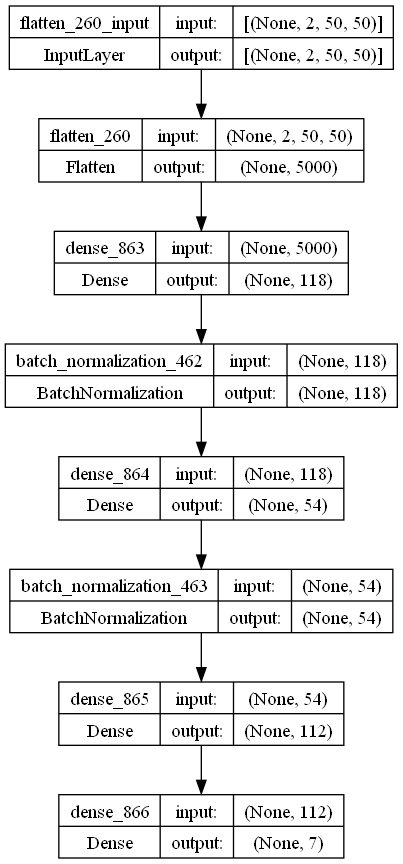

In [29]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [30]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [31]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [32]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [33]:
model.compile(optimizer=optimizer,
              loss= custom_loss,
              metrics=metrics)

In [35]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.0001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 10000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [36]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 4s 46ms/step - loss: 12.7386 - a_1: 2.6800 - a_2: 2.5571 - b_1: 2.8446 - b_2: 2.7552 - d_1: 0.6550 - d_2: 0.6124 - n: 1.7312 - mean_metric: 0.4322 - val_loss: 33.8503 - val_a_1: 2.6828 - val_a_2: 2.4894 - val_b_1: 2.7672 - val_b_2: 2.7687 - val_d_1: 1.5030 - val_d_2: 1.7012 - val_n: 1.5678 - val_mean_metric: 0.4805 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 3s 41ms/step - loss: 9.2520 - a_1: 2.5688 - a_2: 2.5739 - b_1: 2.8268 - b_2: 2.6289 - d_1: 0.4620 - d_2: 0.4518 - n: 1.5443 - mean_metric: 0.4078 - val_loss: 20.9186 - val_a_1: 2.5600 - val_a_2: 2.5053 - val_b_1: 2.7450 - val_b_2: 2.6682 - val_d_1: 1.1041 - val_d_2: 0.8605 - val_n: 1.5440 - val_mean_metric: 0.4341 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 3s 41ms/step - loss: 8.6691 - a_1: 2.5419 - a_2: 2.5679 - b_1: 2.7589 - b_2: 2.5326 - d_1: 0.4372 - d_2: 0.4238 - n: 1.5809 - mean_metric: 0.4012 - val_loss: 14.0393 - val_a_1: 2.

70/70 [==============================] - 3s 40ms/step - loss: 5.5267 - a_1: 2.4836 - a_2: 2.4970 - b_1: 0.8022 - b_2: 0.7793 - d_1: 0.2349 - d_2: 0.2382 - n: 1.4924 - mean_metric: 0.2663 - val_loss: 4.1149 - val_a_1: 2.4959 - val_a_2: 2.4976 - val_b_1: 0.8429 - val_b_2: 0.8414 - val_d_1: 0.1362 - val_d_2: 0.1983 - val_n: 1.5127 - val_mean_metric: 0.2645 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 3s 40ms/step - loss: 5.0208 - a_1: 2.4837 - a_2: 2.5034 - b_1: 0.7964 - b_2: 0.7542 - d_1: 0.1953 - d_2: 0.2245 - n: 1.4937 - mean_metric: 0.2640 - val_loss: 4.9082 - val_a_1: 2.5117 - val_a_2: 2.4922 - val_b_1: 0.7415 - val_b_2: 0.8588 - val_d_1: 0.1948 - val_d_2: 0.2362 - val_n: 1.4662 - val_mean_metric: 0.2638 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 3s 40ms/step - loss: 5.6282 - a_1: 2.4803 - a_2: 2.4969 - b_1: 0.8061 - b_2: 0.7622 - d_1: 0.2377 - d_2: 0.2449 - n: 1.4805 - mean_metric: 0.2658 - val_loss: 4.7491 - val_a_1: 2.4911 - val_a_2:

70/70 [==============================] - 3s 40ms/step - loss: 4.5555 - a_1: 2.4832 - a_2: 2.4928 - b_1: 0.6961 - b_2: 0.7121 - d_1: 0.1767 - d_2: 0.1841 - n: 1.4310 - mean_metric: 0.2554 - val_loss: 4.1489 - val_a_1: 2.5000 - val_a_2: 2.4918 - val_b_1: 0.9088 - val_b_2: 0.8120 - val_d_1: 0.1563 - val_d_2: 0.1530 - val_n: 1.4795 - val_mean_metric: 0.2638 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 3s 40ms/step - loss: 4.5223 - a_1: 2.4822 - a_2: 2.4919 - b_1: 0.6802 - b_2: 0.6850 - d_1: 0.1874 - d_2: 0.1732 - n: 1.4386 - mean_metric: 0.2542 - val_loss: 4.5296 - val_a_1: 2.5020 - val_a_2: 2.4892 - val_b_1: 0.7766 - val_b_2: 1.2692 - val_d_1: 0.1727 - val_d_2: 0.1914 - val_n: 1.5017 - val_mean_metric: 0.2762 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 3s 40ms/step - loss: 4.8359 - a_1: 2.4865 - a_2: 2.4850 - b_1: 0.7158 - b_2: 0.7196 - d_1: 0.1974 - d_2: 0.1963 - n: 1.4285 - mean_metric: 0.2571 - val_loss: 4.1889 - val_a_1: 2.5063 - val_a_2:

70/70 [==============================] - 3s 40ms/step - loss: 4.0835 - a_1: 2.4916 - a_2: 2.4915 - b_1: 0.6466 - b_2: 0.7007 - d_1: 0.1533 - d_2: 0.1574 - n: 1.4094 - mean_metric: 0.2515 - val_loss: 3.9808 - val_a_1: 2.5129 - val_a_2: 2.4745 - val_b_1: 0.6287 - val_b_2: 0.6956 - val_d_1: 0.1380 - val_d_2: 0.1532 - val_n: 1.4553 - val_mean_metric: 0.2501 - lr: 9.9764e-04
Epoch 128/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.9480 - a_1: 2.4886 - a_2: 2.4881 - b_1: 0.6373 - b_2: 0.6699 - d_1: 0.1545 - d_2: 0.1420 - n: 1.4027 - mean_metric: 0.2494 - val_loss: 3.6430 - val_a_1: 2.5195 - val_a_2: 2.4824 - val_b_1: 1.0761 - val_b_2: 0.9964 - val_d_1: 0.1185 - val_d_2: 0.0828 - val_n: 1.4829 - val_mean_metric: 0.2717 - lr: 9.9755e-04
Epoch 129/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.6530 - a_1: 2.4988 - a_2: 2.4886 - b_1: 0.6221 - b_2: 0.6649 - d_1: 0.1266 - d_2: 0.1318 - n: 1.4049 - mean_metric: 0.2479 - val_loss: 3.4321 - val_a_1: 2.5109 

70/70 [==============================] - 3s 40ms/step - loss: 3.4370 - a_1: 2.4918 - a_2: 2.4938 - b_1: 0.5903 - b_2: 0.5661 - d_1: 0.1279 - d_2: 0.1144 - n: 1.3578 - mean_metric: 0.2418 - val_loss: 4.1448 - val_a_1: 2.5212 - val_a_2: 2.5106 - val_b_1: 0.4985 - val_b_2: 1.1845 - val_d_1: 0.1056 - val_d_2: 0.2254 - val_n: 1.4278 - val_mean_metric: 0.2629 - lr: 9.9382e-04
Epoch 170/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.5067 - a_1: 2.4912 - a_2: 2.4918 - b_1: 0.5464 - b_2: 0.5559 - d_1: 0.1226 - d_2: 0.1276 - n: 1.3506 - mean_metric: 0.2401 - val_loss: 3.4298 - val_a_1: 2.5137 - val_a_2: 2.4657 - val_b_1: 0.4556 - val_b_2: 0.8576 - val_d_1: 0.1429 - val_d_2: 0.0982 - val_n: 1.3882 - val_mean_metric: 0.2458 - lr: 9.9373e-04
Epoch 171/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.7038 - a_1: 2.4886 - a_2: 2.4895 - b_1: 0.5509 - b_2: 0.5644 - d_1: 0.1455 - d_2: 0.1239 - n: 1.3496 - mean_metric: 0.2409 - val_loss: 4.2299 - val_a_1: 2.5292 

70/70 [==============================] - 3s 40ms/step - loss: 3.5516 - a_1: 2.4910 - a_2: 2.4948 - b_1: 0.4850 - b_2: 0.5350 - d_1: 0.1146 - d_2: 0.1448 - n: 1.3053 - mean_metric: 0.2365 - val_loss: 4.6859 - val_a_1: 2.5173 - val_a_2: 2.4598 - val_b_1: 0.7609 - val_b_2: 0.7241 - val_d_1: 0.1612 - val_d_2: 0.2672 - val_n: 1.3184 - val_mean_metric: 0.2547 - lr: 9.9000e-04
Epoch 212/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.3550 - a_1: 2.4879 - a_2: 2.4966 - b_1: 0.5253 - b_2: 0.5177 - d_1: 0.1175 - d_2: 0.1193 - n: 1.3130 - mean_metric: 0.2367 - val_loss: 3.5355 - val_a_1: 2.5051 - val_a_2: 2.4630 - val_b_1: 0.4892 - val_b_2: 0.8025 - val_d_1: 0.1487 - val_d_2: 0.0820 - val_n: 1.3199 - val_mean_metric: 0.2423 - lr: 9.8991e-04
Epoch 213/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.1336 - a_1: 2.4900 - a_2: 2.4974 - b_1: 0.4836 - b_2: 0.5415 - d_1: 0.1033 - d_2: 0.1073 - n: 1.3057 - mean_metric: 0.2352 - val_loss: 3.6309 - val_a_1: 2.5106 

70/70 [==============================] - 3s 40ms/step - loss: 3.1728 - a_1: 2.4830 - a_2: 2.4950 - b_1: 0.5113 - b_2: 0.5089 - d_1: 0.1172 - d_2: 0.1070 - n: 1.2789 - mean_metric: 0.2344 - val_loss: 4.3423 - val_a_1: 2.4938 - val_a_2: 2.4742 - val_b_1: 0.4954 - val_b_2: 1.8092 - val_d_1: 0.1052 - val_d_2: 0.2775 - val_n: 1.3821 - val_mean_metric: 0.2804 - lr: 9.8618e-04
Epoch 254/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.3115 - a_1: 2.4833 - a_2: 2.4971 - b_1: 0.5007 - b_2: 0.5289 - d_1: 0.1228 - d_2: 0.1132 - n: 1.2813 - mean_metric: 0.2352 - val_loss: 2.6028 - val_a_1: 2.5153 - val_a_2: 2.4576 - val_b_1: 0.5171 - val_b_2: 0.9294 - val_d_1: 0.1022 - val_d_2: 0.0853 - val_n: 1.3180 - val_mean_metric: 0.2459 - lr: 9.8609e-04
Epoch 255/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.1808 - a_1: 2.4812 - a_2: 2.4912 - b_1: 0.4803 - b_2: 0.4938 - d_1: 0.1103 - d_2: 0.1096 - n: 1.2816 - mean_metric: 0.2326 - val_loss: 3.8894 - val_a_1: 2.5190 

70/70 [==============================] - 3s 40ms/step - loss: 2.8887 - a_1: 2.4875 - a_2: 2.4870 - b_1: 0.4780 - b_2: 0.4937 - d_1: 0.0876 - d_2: 0.1047 - n: 1.2776 - mean_metric: 0.2317 - val_loss: 4.7974 - val_a_1: 2.5078 - val_a_2: 2.4505 - val_b_1: 0.3780 - val_b_2: 1.0308 - val_d_1: 0.3087 - val_d_2: 0.1036 - val_n: 1.3078 - val_mean_metric: 0.2509 - lr: 9.8236e-04
Epoch 296/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.0056 - a_1: 2.4836 - a_2: 2.4872 - b_1: 0.4617 - b_2: 0.5065 - d_1: 0.1001 - d_2: 0.1051 - n: 1.2739 - mean_metric: 0.2317 - val_loss: 3.8065 - val_a_1: 2.5100 - val_a_2: 2.4522 - val_b_1: 0.3932 - val_b_2: 0.4648 - val_d_1: 0.2020 - val_d_2: 0.1061 - val_n: 1.2730 - val_mean_metric: 0.2297 - lr: 9.8227e-04
Epoch 297/1000
70/70 [==============================] - 3s 40ms/step - loss: 3.0902 - a_1: 2.4813 - a_2: 2.4914 - b_1: 0.4690 - b_2: 0.4432 - d_1: 0.1033 - d_2: 0.1140 - n: 1.2807 - mean_metric: 0.2306 - val_loss: 5.3905 - val_a_1: 2.5063 

70/70 [==============================] - 3s 42ms/step - loss: 2.8763 - a_1: 2.4805 - a_2: 2.4818 - b_1: 0.4494 - b_2: 0.4257 - d_1: 0.0979 - d_2: 0.1013 - n: 1.2704 - mean_metric: 0.2283 - val_loss: 3.3436 - val_a_1: 2.5090 - val_a_2: 2.4660 - val_b_1: 0.4168 - val_b_2: 0.4243 - val_d_1: 0.0770 - val_d_2: 0.1994 - val_n: 1.2403 - val_mean_metric: 0.2275 - lr: 9.7855e-04
Epoch 338/1000
70/70 [==============================] - 3s 42ms/step - loss: 3.0762 - a_1: 2.4826 - a_2: 2.4833 - b_1: 0.4722 - b_2: 0.4600 - d_1: 0.1205 - d_2: 0.0940 - n: 1.2697 - mean_metric: 0.2306 - val_loss: 2.7604 - val_a_1: 2.5008 - val_a_2: 2.4656 - val_b_1: 0.3467 - val_b_2: 0.4145 - val_d_1: 0.0906 - val_d_2: 0.0954 - val_n: 1.2631 - val_mean_metric: 0.2227 - lr: 9.7845e-04
Epoch 339/1000
70/70 [==============================] - 3s 42ms/step - loss: 3.0567 - a_1: 2.4840 - a_2: 2.4884 - b_1: 0.4885 - b_2: 0.4958 - d_1: 0.1097 - d_2: 0.1014 - n: 1.2634 - mean_metric: 0.2321 - val_loss: 3.6359 - val_a_1: 2.5296 

70/70 [==============================] - 3s 41ms/step - loss: 2.8110 - a_1: 2.4774 - a_2: 2.4823 - b_1: 0.4413 - b_2: 0.4364 - d_1: 0.0909 - d_2: 0.0961 - n: 1.2654 - mean_metric: 0.2277 - val_loss: 3.7680 - val_a_1: 2.5030 - val_a_2: 2.4604 - val_b_1: 0.5550 - val_b_2: 0.3785 - val_d_1: 0.0876 - val_d_2: 0.1910 - val_n: 1.2567 - val_mean_metric: 0.2306 - lr: 9.7473e-04
Epoch 380/1000
70/70 [==============================] - 3s 41ms/step - loss: 2.8237 - a_1: 2.4786 - a_2: 2.4785 - b_1: 0.4597 - b_2: 0.4147 - d_1: 0.1058 - d_2: 0.0866 - n: 1.2645 - mean_metric: 0.2277 - val_loss: 3.3341 - val_a_1: 2.5177 - val_a_2: 2.4527 - val_b_1: 0.4324 - val_b_2: 0.4023 - val_d_1: 0.1854 - val_d_2: 0.0619 - val_n: 1.2542 - val_mean_metric: 0.2267 - lr: 9.7464e-04
Epoch 381/1000
70/70 [==============================] - 3s 41ms/step - loss: 2.8251 - a_1: 2.4787 - a_2: 2.4818 - b_1: 0.4677 - b_2: 0.4399 - d_1: 0.1041 - d_2: 0.0887 - n: 1.2674 - mean_metric: 0.2289 - val_loss: 3.2288 - val_a_1: 2.5124 

70/70 [==============================] - 3s 41ms/step - loss: 2.5587 - a_1: 2.4723 - a_2: 2.4784 - b_1: 0.4174 - b_2: 0.4087 - d_1: 0.0848 - d_2: 0.0826 - n: 1.2570 - mean_metric: 0.2250 - val_loss: 3.6759 - val_a_1: 2.5109 - val_a_2: 2.4618 - val_b_1: 0.6846 - val_b_2: 0.7219 - val_d_1: 0.0641 - val_d_2: 0.1549 - val_n: 1.2923 - val_mean_metric: 0.2448 - lr: 9.7091e-04
Epoch 421: early stopping


# Analizamos accuracy y loss

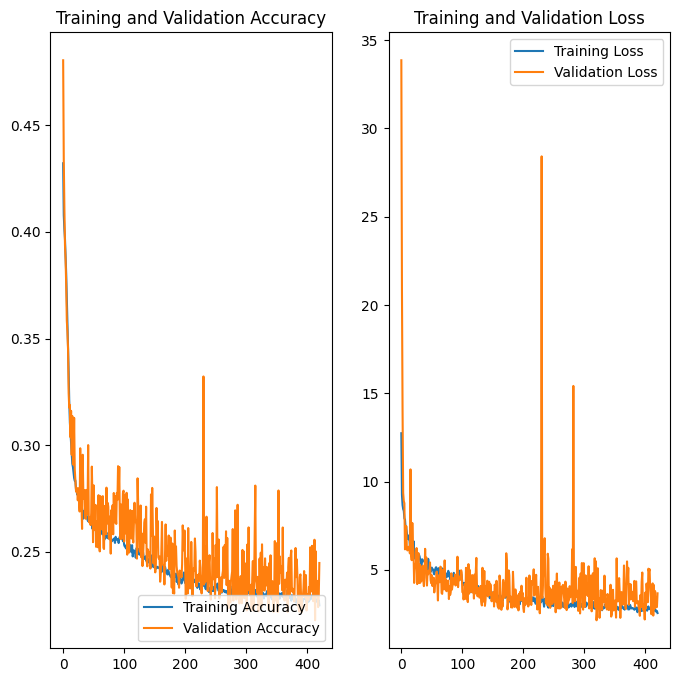

In [37]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(421)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

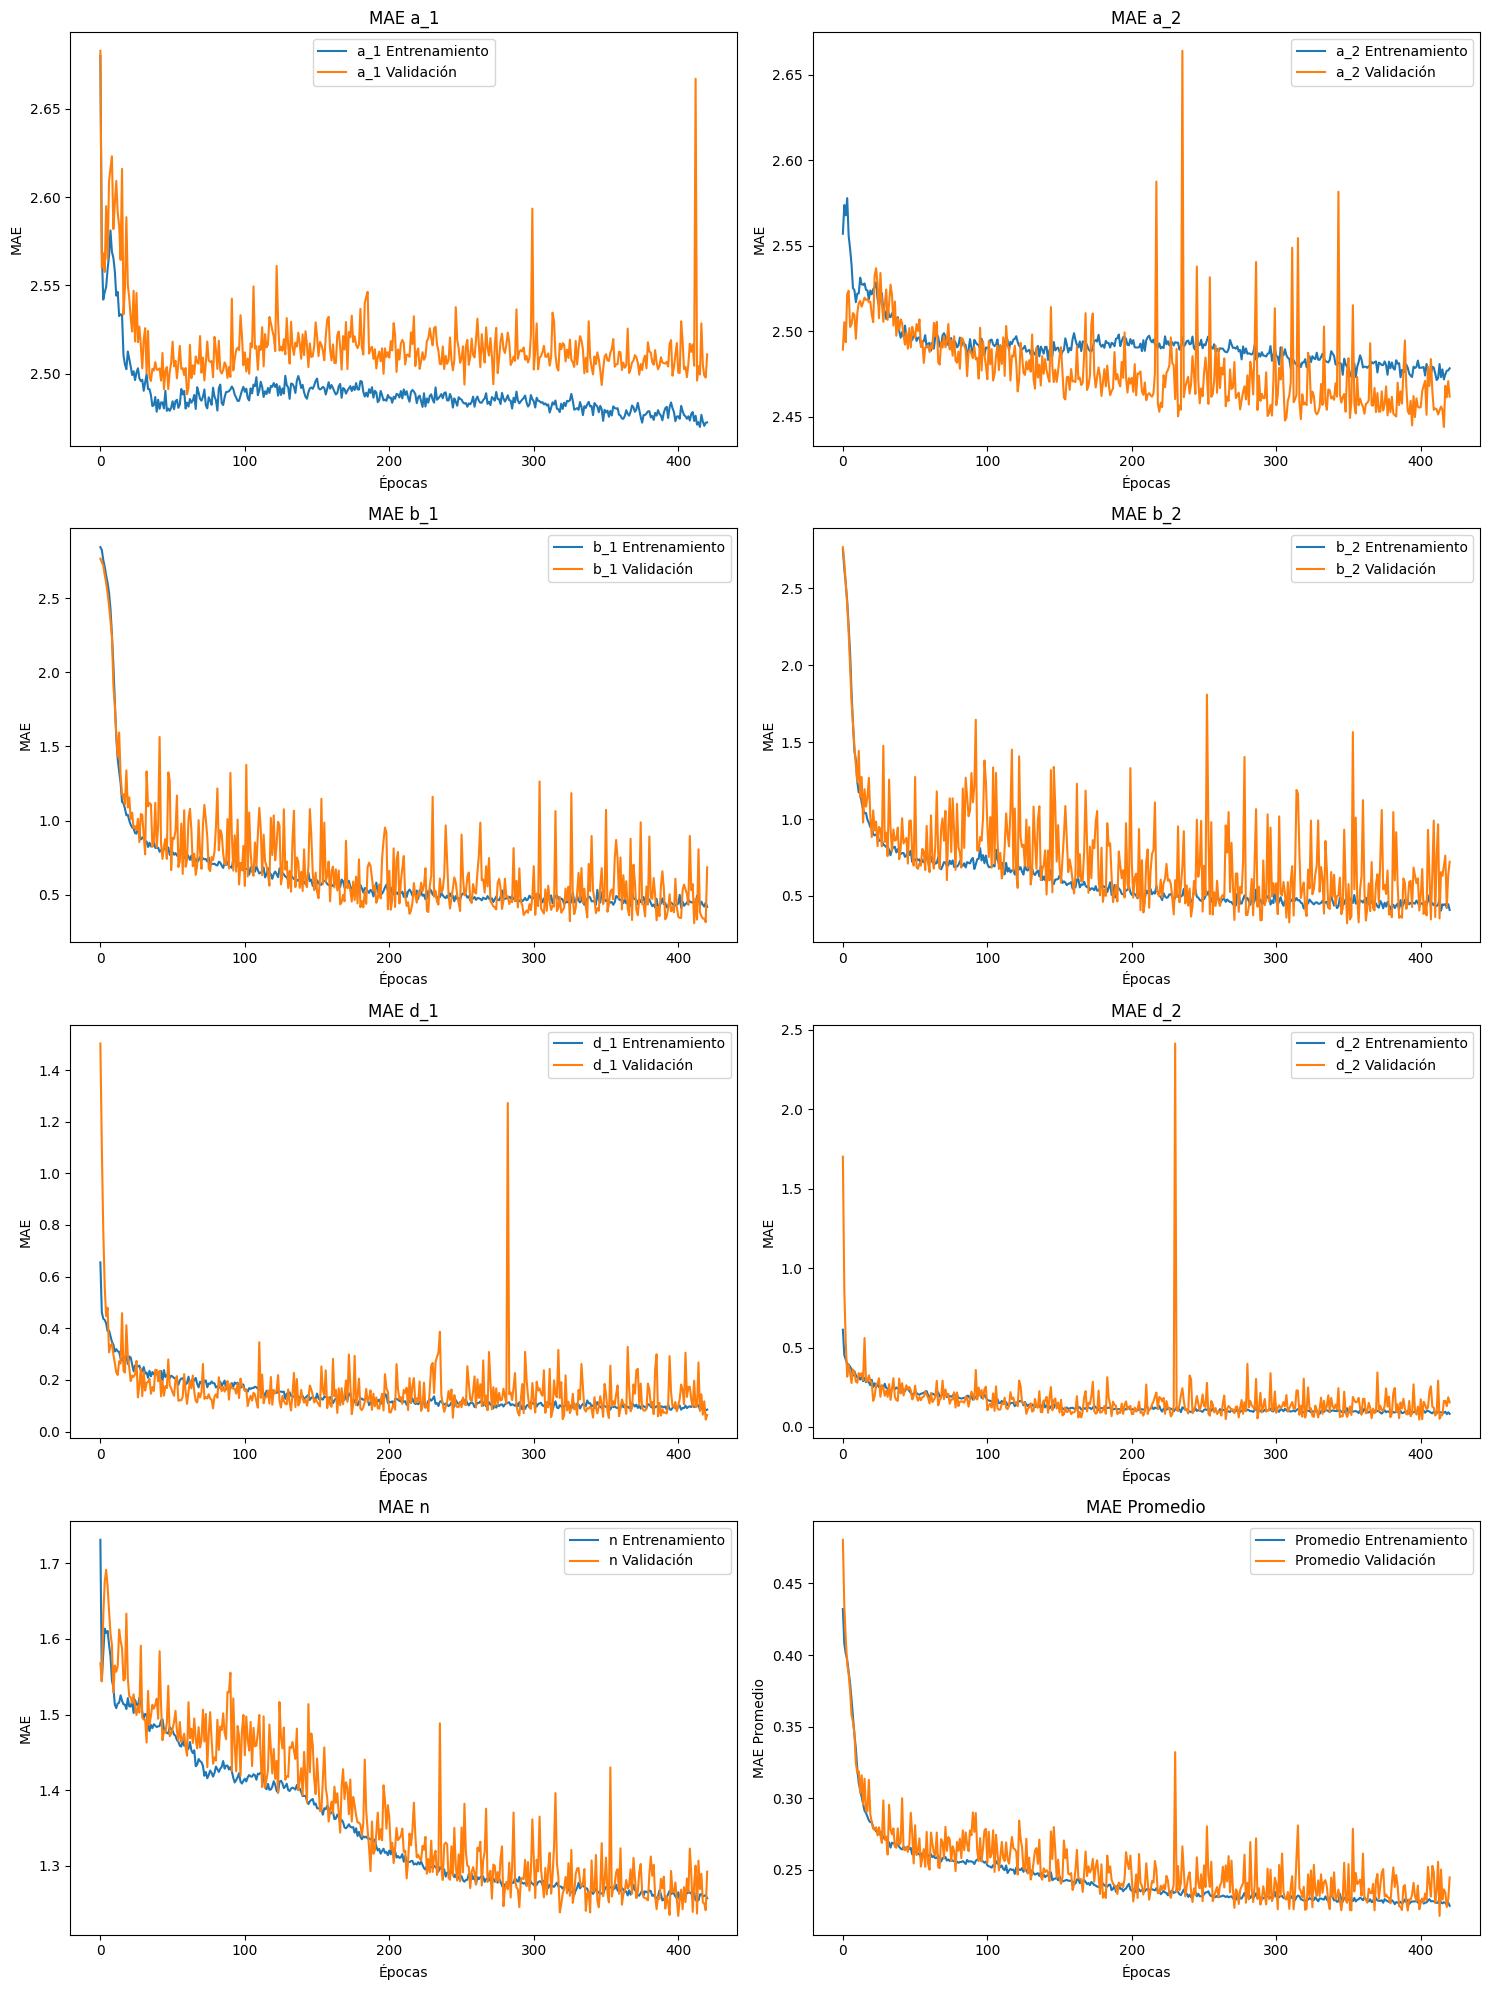

In [38]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [39]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 1s 8ms/step - loss: 2.1628 - a_1: 2.5163 - a_2: 2.4750 - b_1: 0.3854 - b_2: 0.4175 - d_1: 0.0503 - d_2: 0.0614 - n: 1.2707 - mean_metric: 0.2231


In [40]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 2ms/step


In [41]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 1.0257875583161282, Desviación estándar del error: 1.668202548510958, Error absoluto máximo: 5.727171421051025


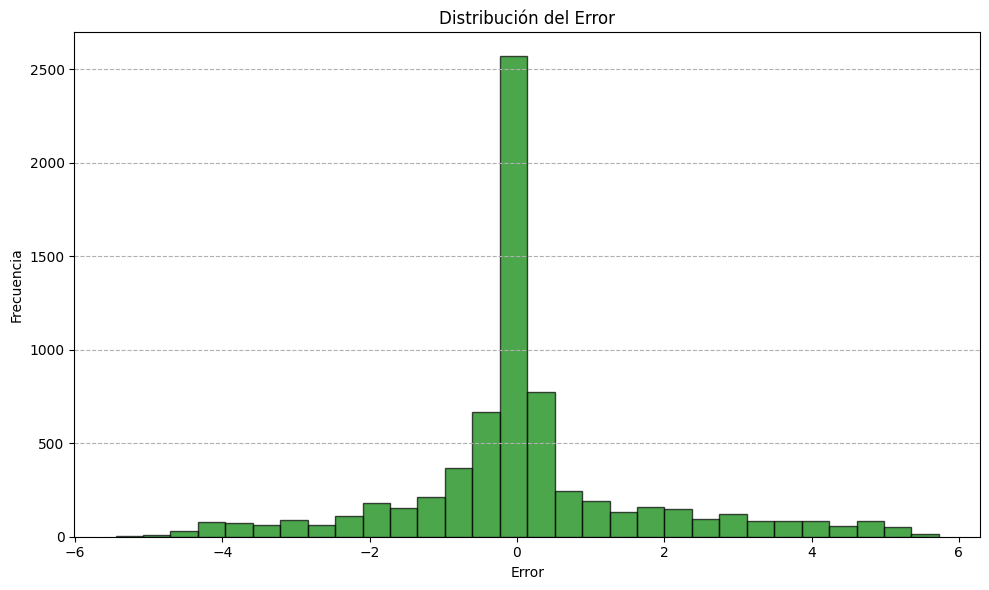

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [43]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.220366957751581
Desviación estándar del error relativo: 0.1396249461486332
Error absoluto máximo relativo: 0.5834180787205696


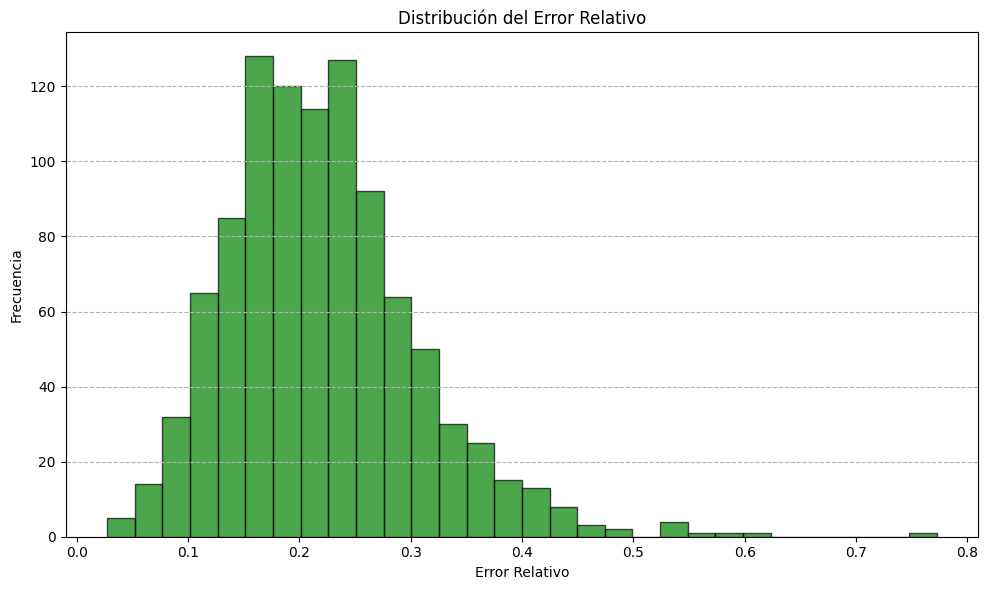

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos de Accuracy y Loss

In [45]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid50_traj100/historycampvec50funcioncosto.csv', index = False)

# Guardamos el modelo

In [46]:
path_to_save = '../../../trained_models_clean/grid50_traj100'
path_to_save = '../../../trained_models_clean/grid50_traj100'

In [47]:
model.save(path_to_save + '/campovectorial50funcioncosto.h5')

# Importamos el modelo

In [1]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [2]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [5]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_loss':custom_loss,'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_clean/grid50_traj100/campovectorial50funcioncosto.h5', 
                                    custom_objects=custom_objects)

In [7]:
new_model.summary()

Model: "sequential_260"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_260 (Flatten)       (None, 5000)              0         
                                                                 
 dense_863 (Dense)           (None, 118)               590118    
                                                                 
 batch_normalization_462 (Ba  (None, 118)              472       
 tchNormalization)                                               
                                                                 
 dense_864 (Dense)           (None, 54)                6426      
                                                                 
 batch_normalization_463 (Ba  (None, 54)               216       
 tchNormalization)                                               
                                                                 
 dense_865 (Dense)           (None, 112)            

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [51]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b1

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[9, 3, 1, 4, 0, 0, 5]


In [52]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [53]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 48ms/step
[[4. 5. 1. 1. 0. 0. 2.]]


## Encontramos puntos de equilibrio datos reales

In [57]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(146990897.8961532, 130213681.8961166)


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

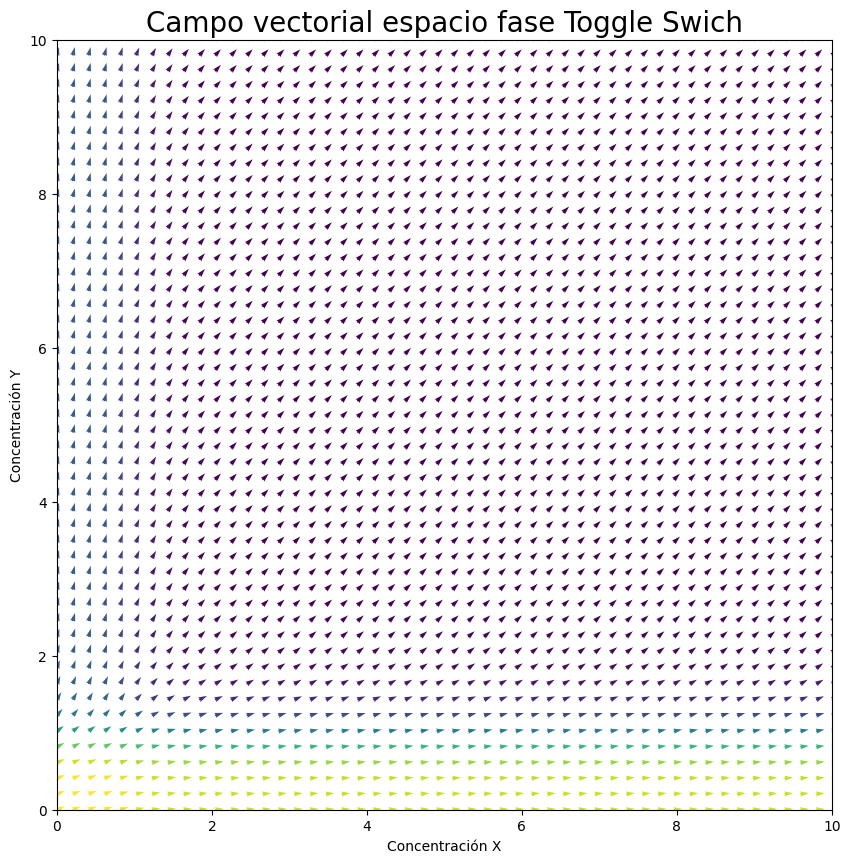

In [62]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 50)
y2 = np.linspace(0, 10, 50)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibrio datos predecidos

In [58]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(146990897.8961532, 130213681.8961166)


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

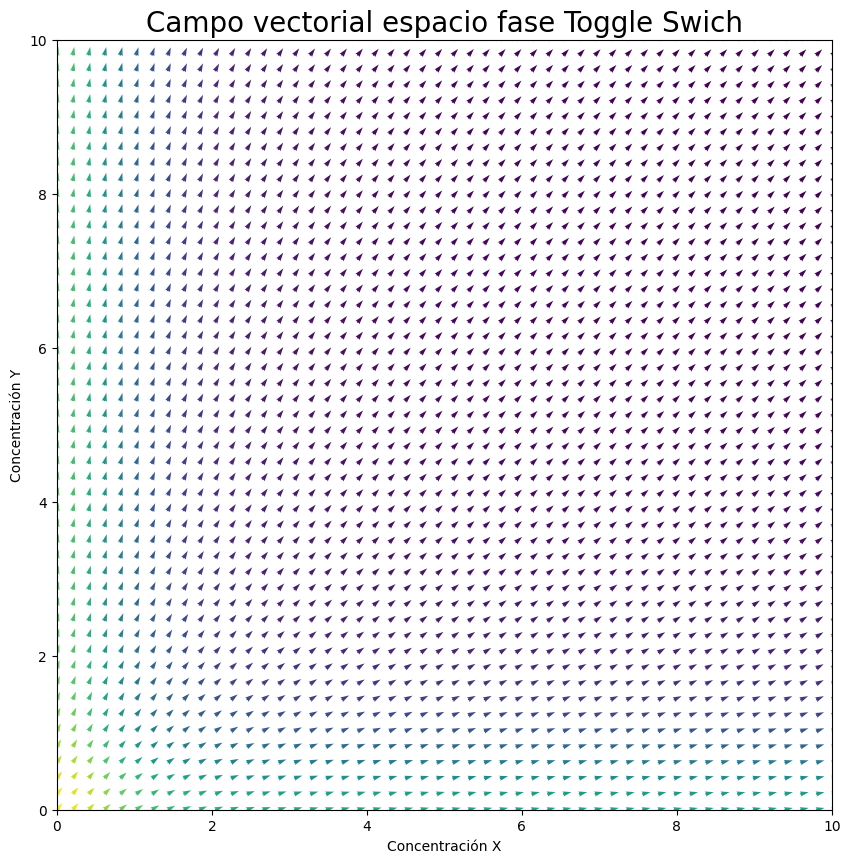

In [60]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 50)
y2pred = np.linspace(y_range_neg, y_range_pos, 50)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

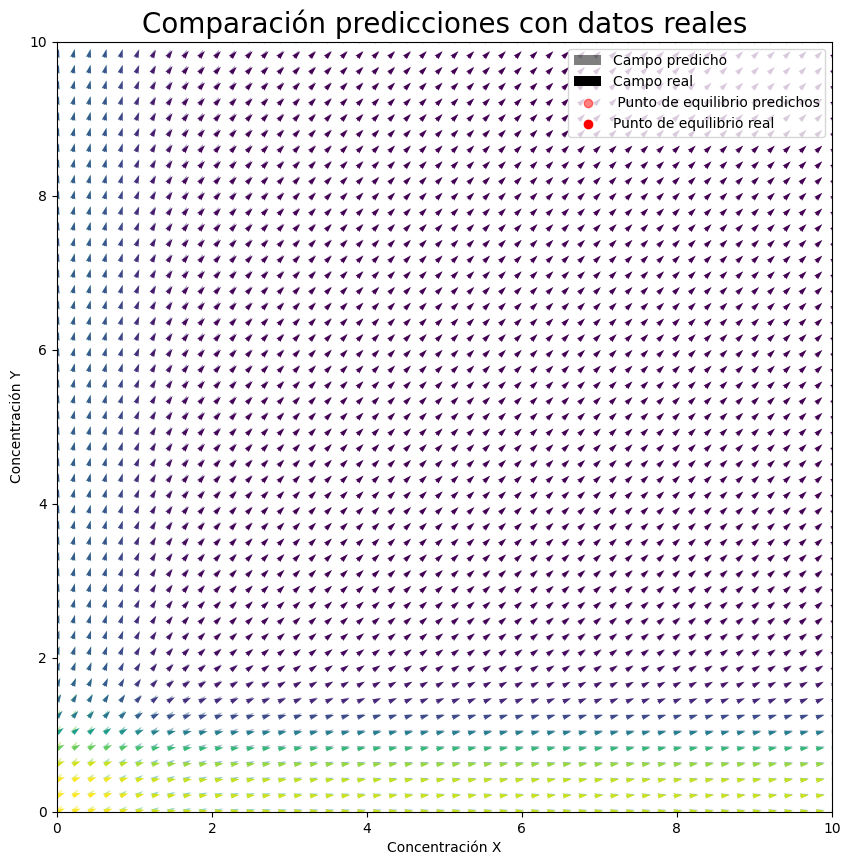

In [63]:
#%matplotlib qt
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5, label = "Campo predicho")

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1, label = "Campo real")

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5, label = " Punto de equilibrio predichos")
ax.scatter(x_values, y_values, color='red', alpha = 1, label = "Punto de equilibrio real")
ax.set_title('Comparación predicciones con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')
ax.legend(loc='upper right')  # Agregar leyenda a la gráfica
plt.show()

## Grafimcamos las diferencias

17.347213262259935


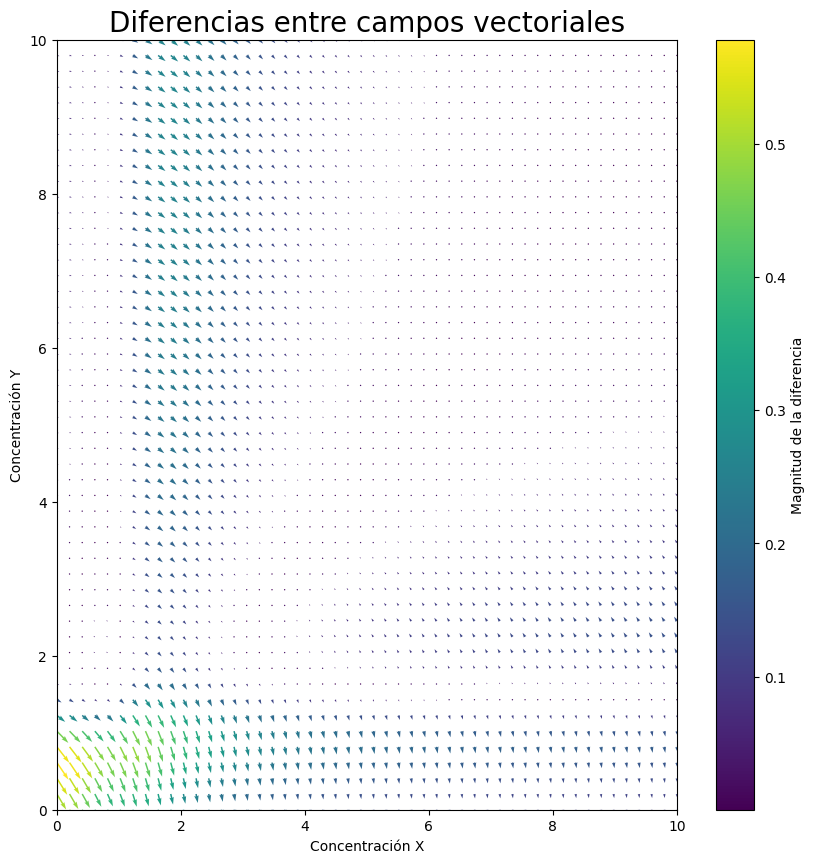

In [64]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

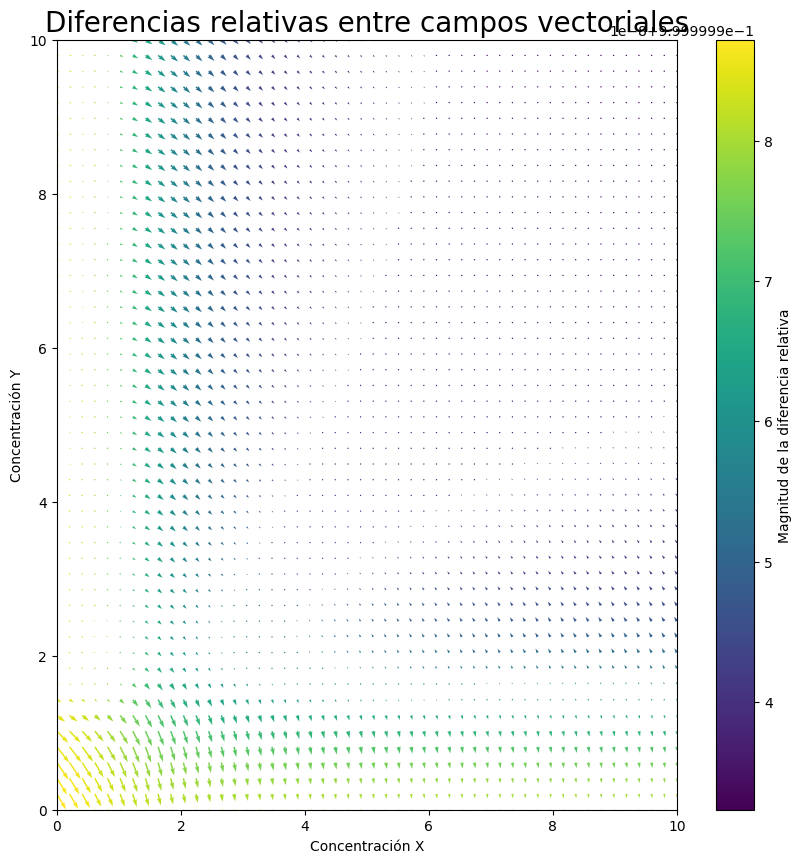

In [65]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [66]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 0.9999999871963121
El valor de u1 en el error relativo máximo es: 5.0
El valor de u1pred en el error relativo máximo es: 5.0
El valor de v1 en el error relativo máximo es: 6.0
El valor de v1pred en el error relativo máximo es: 6.0


In [67]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 58.96%


## Hacemos esto n veces

In [68]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 50)
    y2pred = np.linspace(y_range_neg, y_range_pos, 50)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 48ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 95.16%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 98.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 88.24%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 96.64%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 78.92%
--------------------------------------------
1/1 [=========================

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 88.12%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 99.88%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 99.72%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 77.76%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 98.96%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de p

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 95.08%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 43.96%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 99.92%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 99.32%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 97.40%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 99.72%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 99.60%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 89.32%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 92.08%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 47.60%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje

1/1 [==============================] - 0s 9ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 99.88%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 90.76%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 99.56%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 100.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 86.80%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 265 es 91.56%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 266 es 97.76%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 267 es 89.04%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 268 es 62.40%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 269 es 99.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

... (217 outputs left out)

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9816 es 99.12%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9817 es 96.12%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9818 es 91.88%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9819 es 98.68%
--------------------------------------------
1/1 [==============================] - 0s 9ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9820 es 94.76%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcen

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9860 es 97.20%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9861 es 91.32%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9862 es 98.60%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9863 es 96.92%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9864 es 98.12%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porce

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9904 es 79.04%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9905 es 99.84%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9906 es 99.40%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9907 es 76.32%
--------------------------------------------
1/1 [==============================] - 0s 9ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9908 es 96.92%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcen

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9948 es 88.84%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9949 es 95.36%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9950 es 98.24%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9951 es 97.20%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9952 es 92.48%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porce

El promedio de los porcentajes es 91.12%


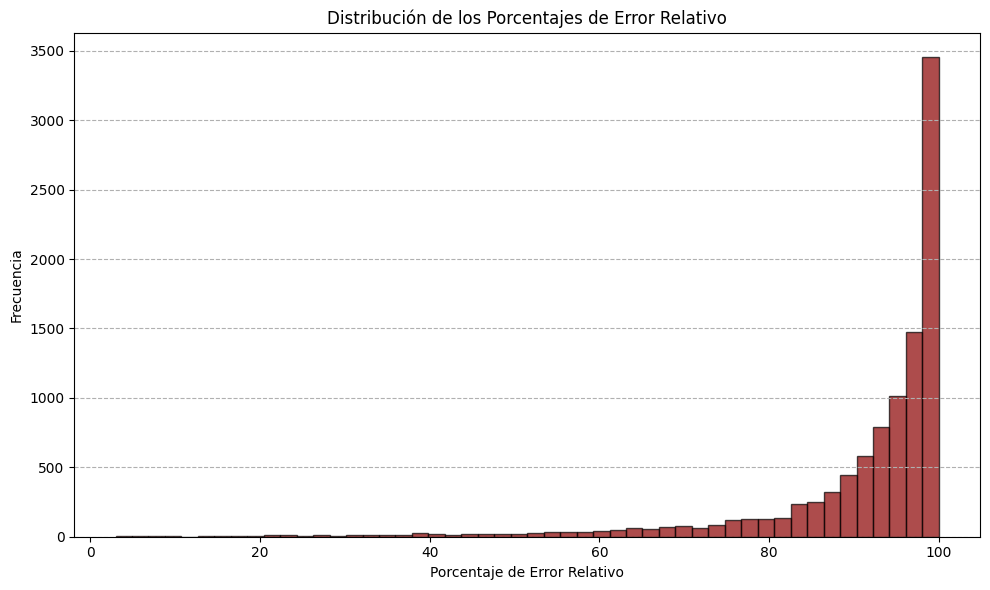

In [69]:
import matplotlib.pyplot as plt

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()